# Performance comparison — dynamic range & quantification spread

Continuation of `02_Settings_comparison.ipynb`. Where notebook 02 compared settings on the
count-vs-error overview level, this notebook focuses on the **dynamic range** and the
**quantification spread / accuracy** of each tool, using only the single best setting per tool.

The analysis works on the `datapoints` and `intermediates` objects produced by
`01_parse_results_clean.ipynb`, restricted to:

```
best_settings = {
    'AlphaDIA':                'Default',
    'MSAID':                   '5.0.0 MS2(Area) TIC-norm',
    'DIA-NN':                  'DIANN 2.6',
    'FragPipe (DIA-NN quant)': 'standard',
    'PEAKS':                   'MBR TIC-norm',
    'Spectronaut':             'DirectDIA+ method-evaluation',
}
```

but also available on [Zenodo](https://doi.org/10.5281/zenodo.21181080) at `./Data/ProteoBench`

The benchmark is a three-species mix (HUMAN, YEAST, ECOLI) with known A-vs-B ratios, so each
precursor has an expected log2 fold change and a measured one. The signed error
`epsilon = measured - expected` is already stored in `intermediates`.

Figures:
1. **KDE** of log2 fold changes per lab and species.
2. **MA-plots** — one per tool: mean abundance vs measured log2 fold change, with the expected
   per-species ratios drawn as dotted lines.
3. **Pairwise tool comparison** — for matching precursors, the difference in error from the
   expected fold change across the abundance range, split per species.


## 1. Imports, load & restrict to best settings


In [1]:
import os
import pickle

import pandas as pd
import matplotlib.pyplot as plt

from SCI_py.constants import SOFTWARE_COLORS
from SCI_py.plot import (
    plot_species_distributions,
    plot_ma_per_tool,
    plot_ma_multilab,
    plot_dynamic_range_multi,
    compare_tools_error,
)

FIGURE_PATH = '/home/sam/SCI/SCI/Figures/Figure_2/dynamic_range'
ZENODO_FOLDER = '/public/conode53/sam/SCI_paper/Zenodo'

In [2]:
DATA_PATH = os.path.join(ZENODO_FOLDER, 'Data', 'ProteoBench')

with open(os.path.join(DATA_PATH, 'datapoints.pkl'), 'rb') as f:
    datapoints = pickle.load(f)
with open(os.path.join(DATA_PATH, 'intermediates.pkl'), 'rb') as f:
    intermediates = pickle.load(f)

print(f'{len(datapoints)} datapoints  |  {len(intermediates):,} intermediate rows')

# ── Best setting per tool ─────────────────────────────────────────────────────
best_settings = {
    'AlphaDIA':                'Default',
    'MSAID':                   '5.0.0 MS2(Area) TIC-norm',
    'DIA-NN':                  'DIANN 2.6',
    'FragPipe (DIA-NN quant)': 'standard',
    'PEAKS':                   'MBR TIC-norm',
    'Spectronaut':             'DirectDIA+ method-evaluation',
}
non_tic_settings = {
    'AlphaDIA':                'Default',
    'MSAID':                   '5.0.0 MS2(Area)',
    'DIA-NN':                  'DIANN 2.6',
    'FragPipe (DIA-NN quant)': 'standard',
    'PEAKS':                   'MBR',
    'Spectronaut':             'DirectDIA+ method-evaluation',
}

def filter_best(df, best=best_settings):
    return df[df.apply(lambda r: r['comments'] == best.get(r['search_engine']), axis=1)].copy()


inter = filter_best(intermediates)
dtps  = filter_best(datapoints)

inter_nontic = filter_best(intermediates, best=non_tic_settings)
dtps_nontic = filter_best(datapoints, best=non_tic_settings)

print('\nIntermediate rows per tool (best setting only):')
for tool in best_settings:
    n = (inter['search_engine'] == tool).sum()
    print(f'  {tool:26s} {best_settings[tool]:28s} {n:>9,} rows')

missing = [t for t in best_settings if (inter['search_engine'] == t).sum() == 0]
if missing:
    print(f'\nWARNING - no rows found for: {missing}')


75 datapoints  |  1,020,110 intermediate rows

Intermediate rows per tool (best setting only):
  AlphaDIA                   Default                         98,797 rows
  MSAID                      5.0.0 MS2(Area) TIC-norm        59,209 rows
  DIA-NN                     DIANN 2.6                      161,648 rows
  FragPipe (DIA-NN quant)    standard                        74,784 rows
  PEAKS                      MBR TIC-norm                   123,919 rows
  Spectronaut                DirectDIA+ method-evaluation   146,130 rows


In [3]:
# ── Species ground truth & colours ───────────────────────────────────────────
# Expected log2 ratios are stored per precursor; collapse to one value per species.
exp_log2 = intermediates.groupby('species')['log2_expectedRatio'].first().to_dict()

SPECIES_ORDER  = [s for s in ['HUMAN', 'YEAST', 'ECOLI'] if s in exp_log2]
SPECIES_COLORS = {'HUMAN': '#3B6FB6', 'YEAST': '#E1812C', 'ECOLI': '#3A923A'}

# species_config matches the signature expected by plot_species_distributions:
# {species: {'A_vs_B': linear_ratio, 'color': ...}}
species_config = {
    sp: {'A_vs_B': 2.0 ** exp_log2[sp], 'color': SPECIES_COLORS[sp]}
    for sp in SPECIES_ORDER
}

print('Expected log2 fold changes (A vs B):')
for sp in SPECIES_ORDER:
    print(f'  {sp:6s}: {exp_log2[sp]:+.1f}  (A/B = {2.0 ** exp_log2[sp]:g})')


Expected log2 fold changes (A vs B):
  HUMAN : +0.0  (A/B = 1)
  YEAST : -1.0  (A/B = 0.5)
  ECOLI : +2.0  (A/B = 4)


In [4]:
# ── Select a single lab ──────────────────────────────────────────────────────
# Each lab is a separate dataset, so abundance and fold changes are only comparable
# within one lab. The MA-plot (section 3) and the pairwise error figure (section 4)
# are therefore computed for ONE lab at a time. Change SELECTED_LAB to any value below.
available_labs = sorted(inter['lab'].unique())
print(f'{len(available_labs)} labs available:')
print('  ' + ' | '.join(available_labs))

SELECTED_LAB = available_labs[0]
print(f'\nSelected lab: {SELECTED_LAB}')


9 labs available:
  Astral_1 | Astral_2 | Astral_3 | Astral_4 | Astral_5 | Astral_6 | timsTOF_1 | timsTOF_2 | timsTOF_3

Selected lab: Astral_1


## 2. KDE of log2 fold changes per lab and species

Kernel density estimates of the measured log2 fold change for
each tool, faceted by lab (rows) and species (columns). The dashed vertical line marks the
expected ratio for that species. A tool that quantifies accurately produces a narrow peak
centred on the dashed line.


In [5]:
# plot_species_distributions is imported from SCI_py.plot.performance_comparison

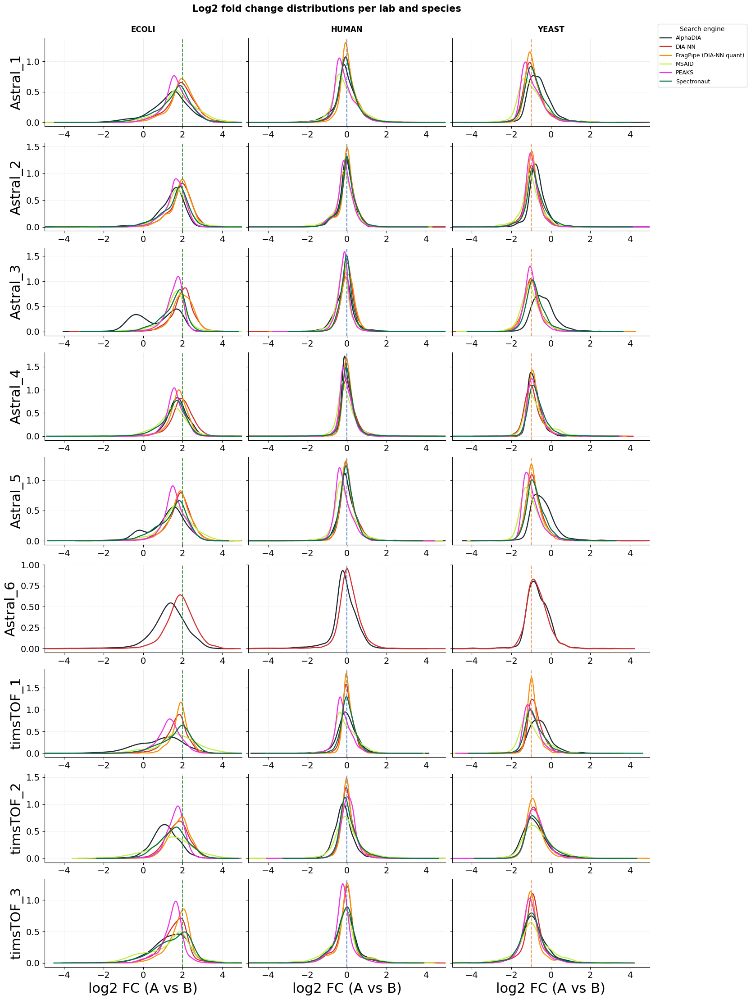

In [6]:
plot_species_distributions(
    intermediates    = inter,
    species_config   = species_config,
    color_map        = SOFTWARE_COLORS,
    normalize_kde    = True,
    xlim_per_species = {'HUMAN': [-5, 5], 'YEAST': [-5, 5], 'ECOLI': [-5, 5]},
    save_dir         = FIGURE_PATH,
    show             = True,
)

Same figure as above but without performing TIC-normalisation

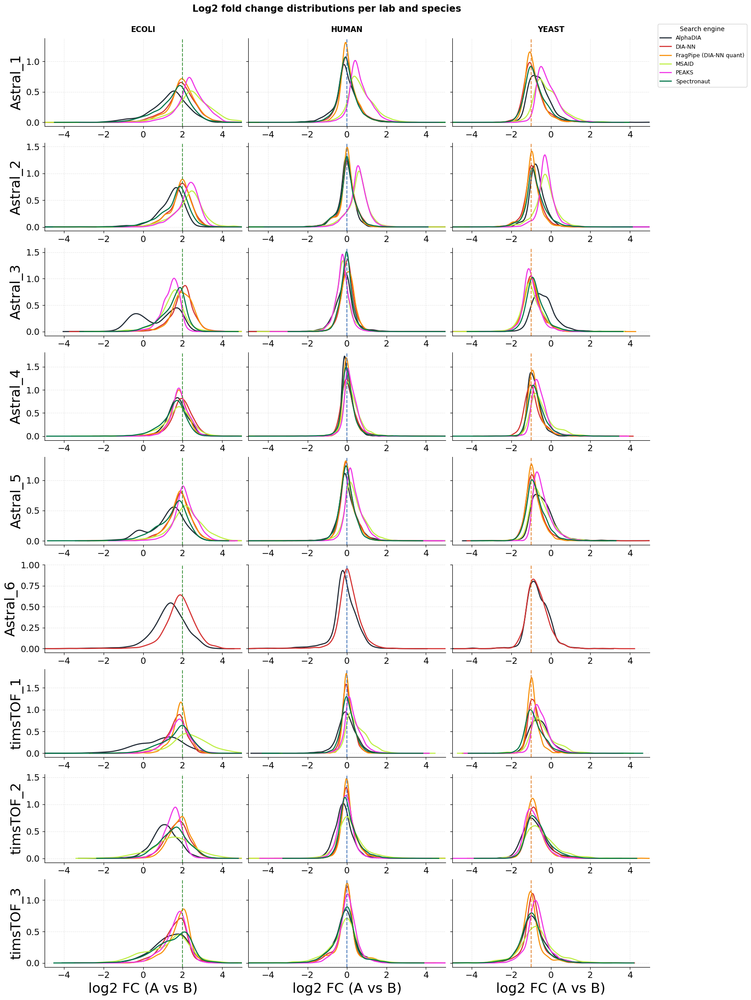

In [7]:
plot_species_distributions(
    intermediates    = inter_nontic,
    species_config   = species_config,
    color_map        = SOFTWARE_COLORS,
    normalize_kde    = True,
    xlim_per_species = {'HUMAN': [-5, 5], 'YEAST': [-5, 5], 'ECOLI': [-5, 5]},
    save_dir         = FIGURE_PATH,
    show             = True,
    filename = 'species_distribution_nontic'
)

## 3. MA-plots per tool (single lab)

Computed for the lab in `SELECTED_LAB`, since each lab is a separate dataset and abundances are
only comparable within a lab. One panel per tool. Following the requested orientation, the
**abundance rank** of a precursor is on the y-axis and the **measured log2 fold change** is on
the x-axis (a transposed MA-plot, so the expected per-species ratios appear as vertical dotted
lines rather than horizontal ones).

- Abundance = mean of the log intensities in conditions A and B, then converted to a percentile
  rank (1 = lowest, 100 = highest) within each tool. Ranking makes the y-axis comparable across
  tools despite their different raw intensity scales.
- Points are coloured by species.
- Dotted vertical lines mark the expected log2 ratio for each species.

A well-behaved tool shows each species' cloud centred on its dotted line across the whole
abundance range, with tighter clouds at high abundance.


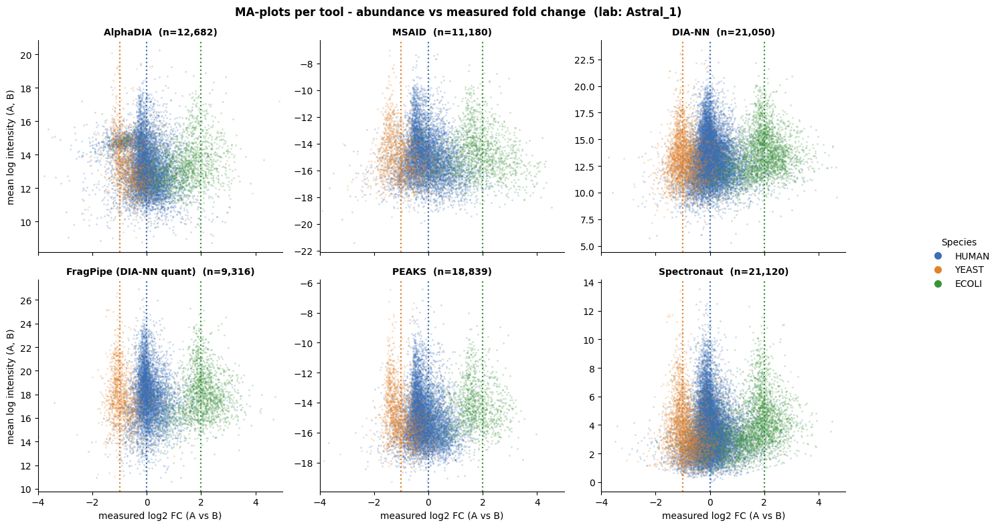

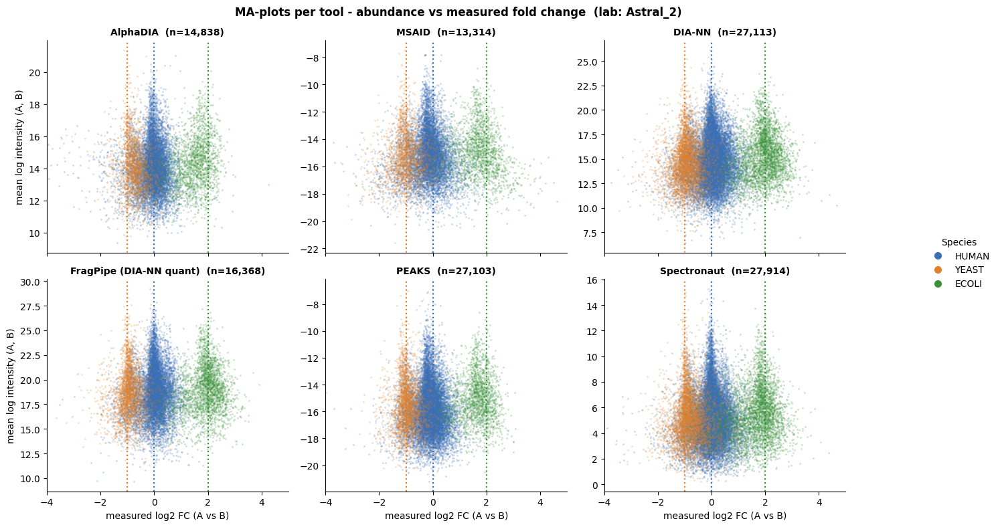

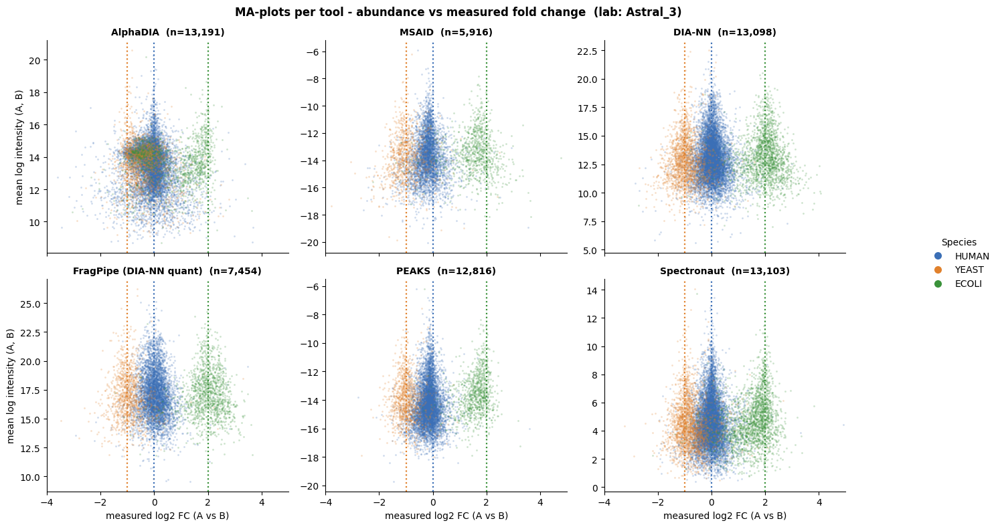

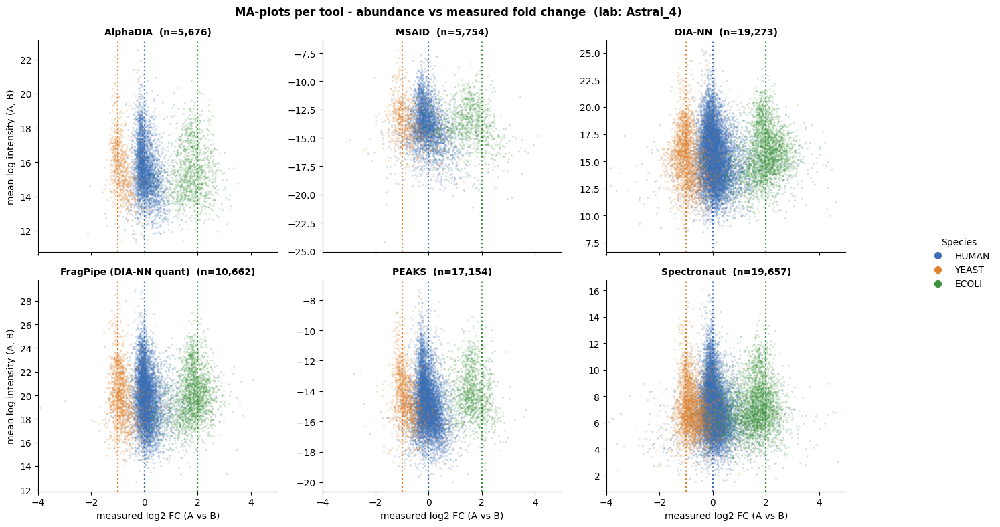

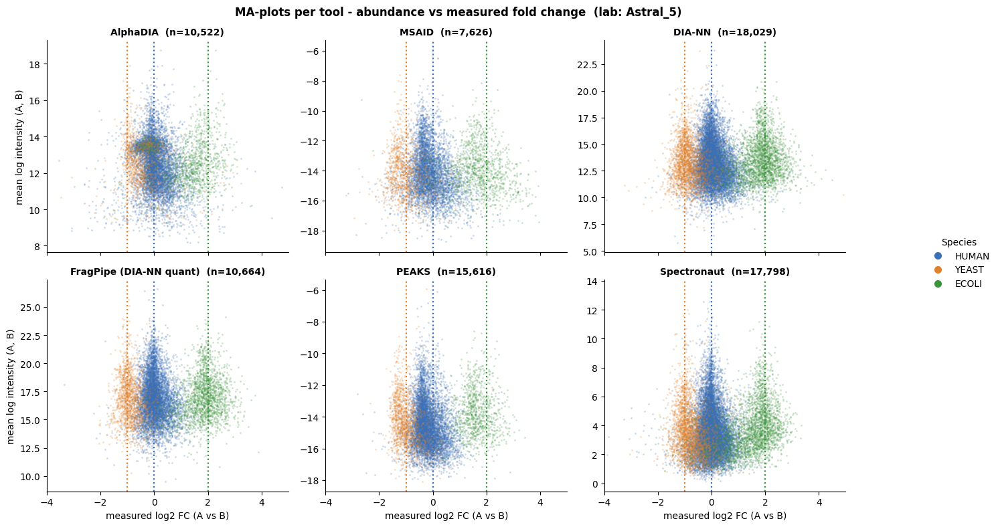

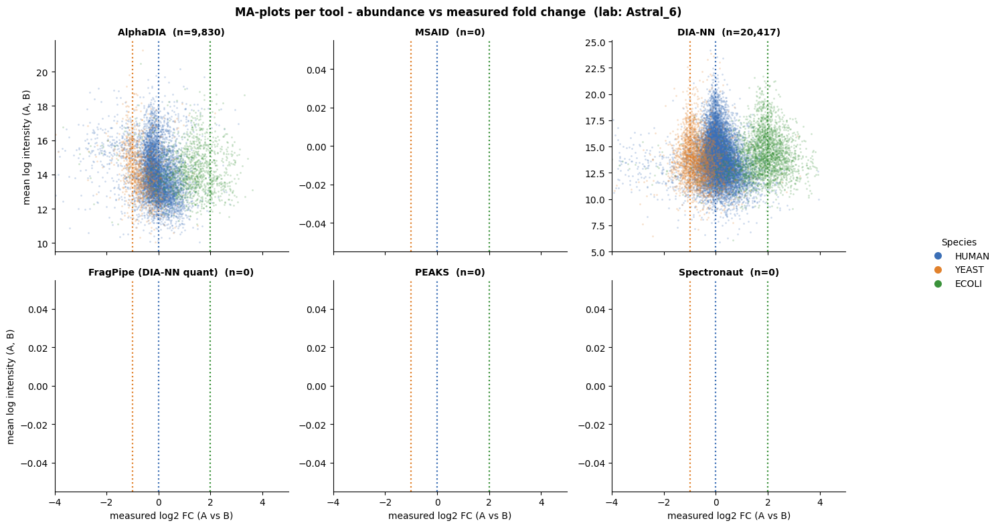

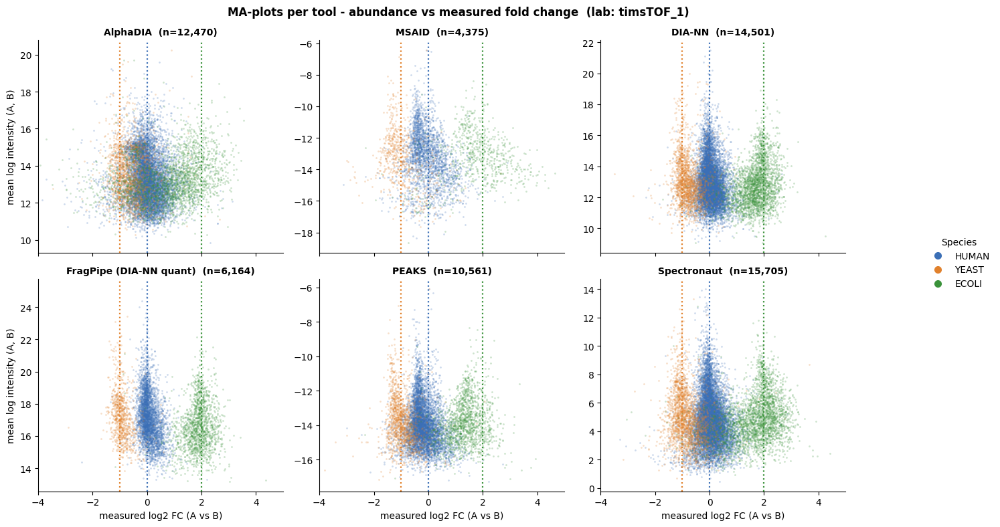

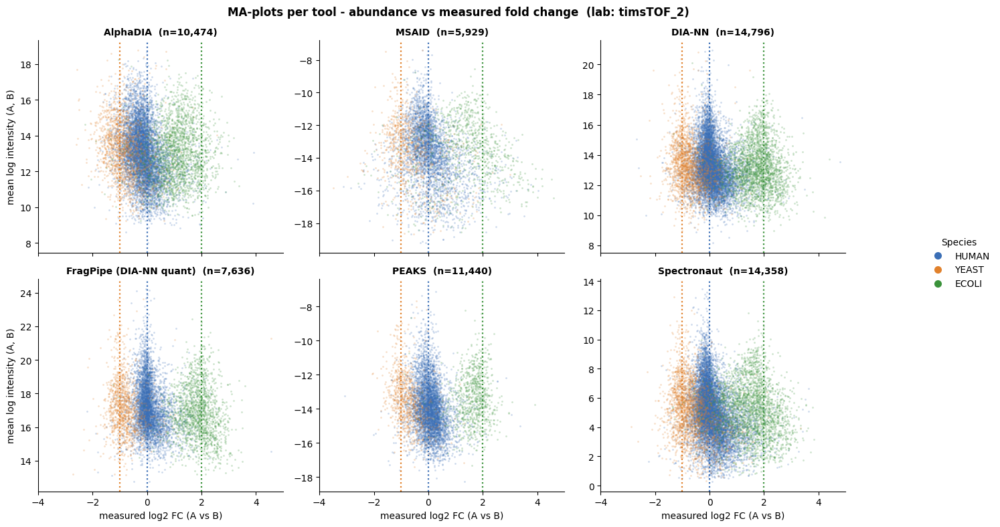

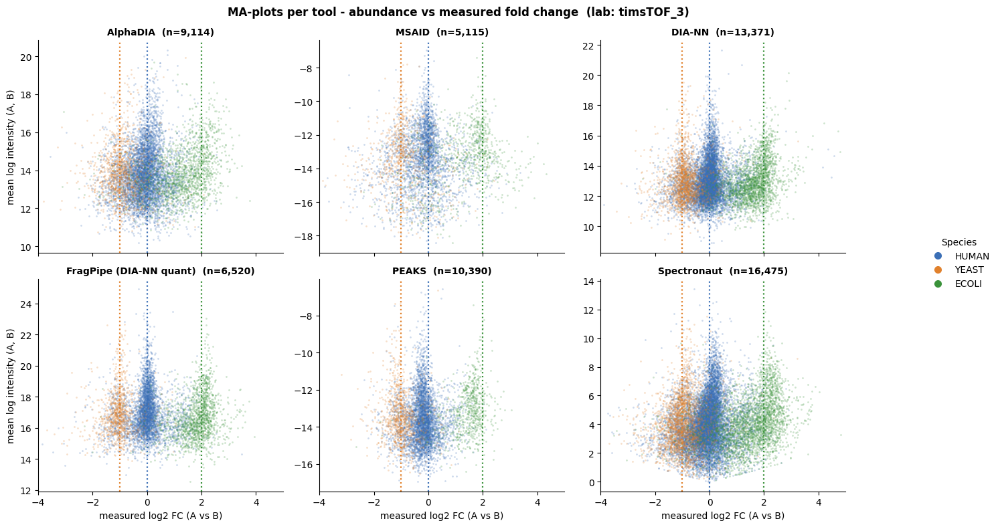

In [8]:
# plot_ma_per_tool is imported from SCI_py.plot.performance_comparison

for lab in available_labs:
    plot_ma_per_tool(
        intermediates  = inter,
        species_config = species_config,
        species_colors = SPECIES_COLORS,
        lab            = lab,
        tools          = list(best_settings.keys()),
        use_rank       = False,
        save_dir       = FIGURE_PATH,
        filename       = f'MAplots_{lab}',
        show           = True,
    )

## 4. Pairwise tool comparison — error vs abundance

`compare_tools_error` takes two `intermediates` subsets (any two tools, or two versions of the
same tool) and a single `lab`, and on **matching precursors** (same precursor ion within that
lab) measures the difference in error from the expected log2 fold change. The lab is selected
because each lab is a separate dataset.

The x-axis is an **abundance rank** rather than raw intensity: each tool's abundance is converted
to a percentile (1 = lowest, 100 = highest) over the matched precursors only. Tools report
intensities on very different scales, so ranking over the shared precursor set makes the
abundance axis comparable. The per-precursor x value is the mean of the two tools' ranks.

For each species (one column per species) it shows two views:

- **Top row** — mean absolute error `|epsilon|` as a function of abundance rank, one line per
  tool. The lower line is the more accurate tool at that abundance.
- **Bottom row** — the paired difference `|epsilon_A| - |epsilon_B|` per abundance-rank bin.
  Values below zero (shaded in tool A's colour) mean tool A is more accurate; values above zero
  (tool B's colour) mean tool B is more accurate.

Matching on precursor within the lab keeps the comparison strictly paired: `delta` for each
precursor is that precursor's `|error|` in tool A minus its `|error|` in tool B.


In [9]:
# compare_tools_error is imported from SCI_py.plot.performance_comparison

DIA-NN vs Spectronaut: 15,852 matched precursors
  HUMAN : DIA-NN more accurate in  49.1% of matched precursors | median |err|: DIA-NN=0.254  Spectronaut=0.252
  YEAST : DIA-NN more accurate in  51.6% of matched precursors | median |err|: DIA-NN=0.260  Spectronaut=0.263
  ECOLI : DIA-NN more accurate in  49.5% of matched precursors | median |err|: DIA-NN=0.385  Spectronaut=0.405


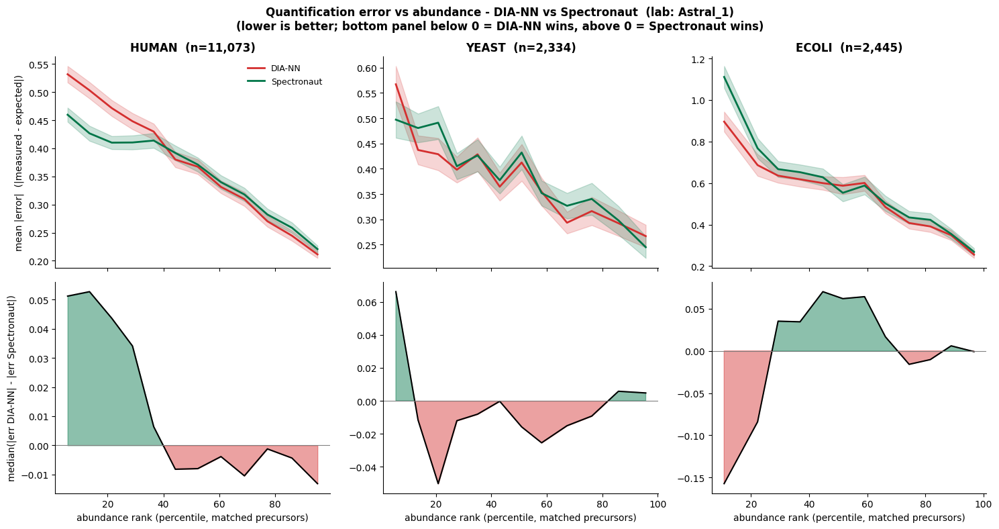

DIA-NN vs Spectronaut: 21,804 matched precursors
  HUMAN : DIA-NN more accurate in  46.3% of matched precursors | median |err|: DIA-NN=0.219  Spectronaut=0.201
  YEAST : DIA-NN more accurate in  51.7% of matched precursors | median |err|: DIA-NN=0.221  Spectronaut=0.235
  ECOLI : DIA-NN more accurate in  53.2% of matched precursors | median |err|: DIA-NN=0.322  Spectronaut=0.317


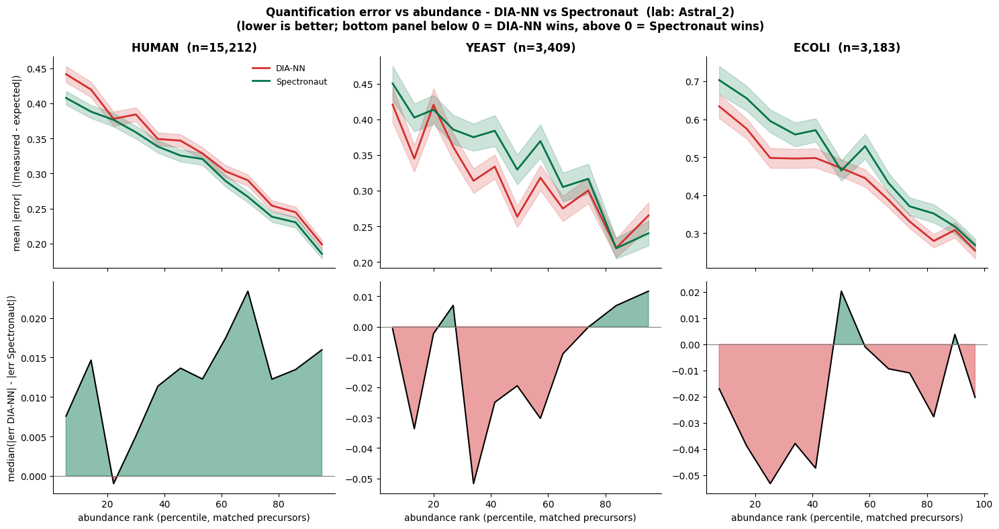

DIA-NN vs Spectronaut: 10,336 matched precursors
  HUMAN : DIA-NN more accurate in  46.1% of matched precursors | median |err|: DIA-NN=0.191  Spectronaut=0.171
  YEAST : DIA-NN more accurate in  49.9% of matched precursors | median |err|: DIA-NN=0.242  Spectronaut=0.238
  ECOLI : DIA-NN more accurate in  52.6% of matched precursors | median |err|: DIA-NN=0.293  Spectronaut=0.320


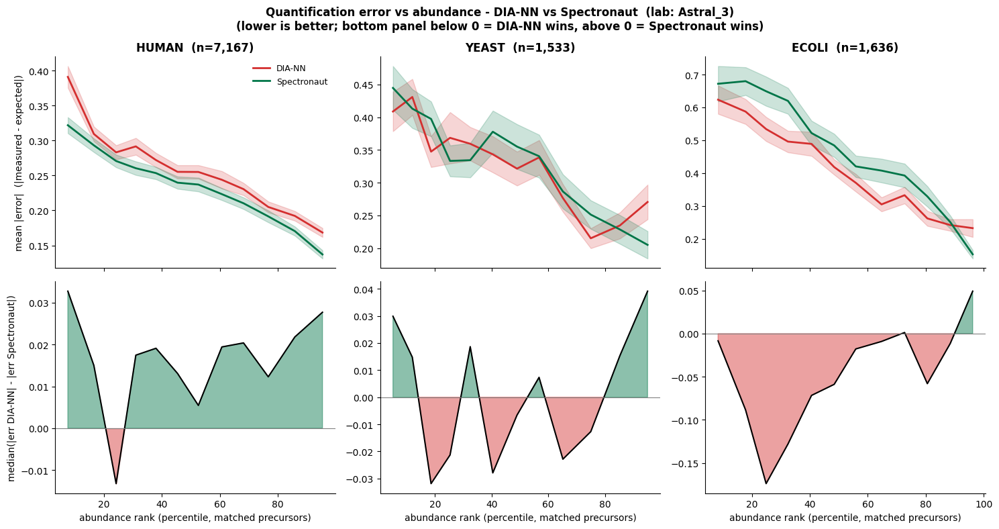

DIA-NN vs Spectronaut: 14,367 matched precursors
  HUMAN : DIA-NN more accurate in  40.1% of matched precursors | median |err|: DIA-NN=0.208  Spectronaut=0.166
  YEAST : DIA-NN more accurate in  50.4% of matched precursors | median |err|: DIA-NN=0.230  Spectronaut=0.228
  ECOLI : DIA-NN more accurate in  57.4% of matched precursors | median |err|: DIA-NN=0.310  Spectronaut=0.357


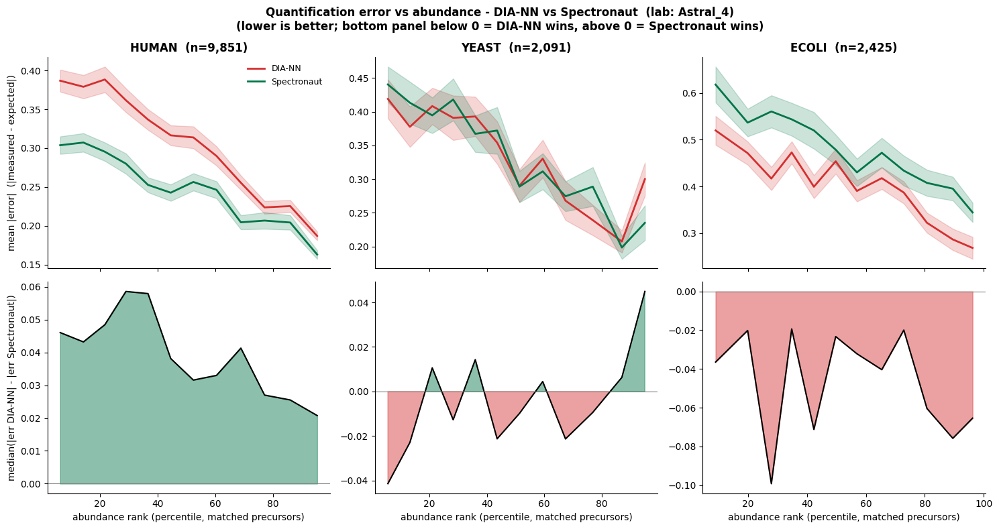

DIA-NN vs Spectronaut: 13,685 matched precursors
  HUMAN : DIA-NN more accurate in  50.6% of matched precursors | median |err|: DIA-NN=0.209  Spectronaut=0.217
  YEAST : DIA-NN more accurate in  51.9% of matched precursors | median |err|: DIA-NN=0.229  Spectronaut=0.256
  ECOLI : DIA-NN more accurate in  54.5% of matched precursors | median |err|: DIA-NN=0.322  Spectronaut=0.372


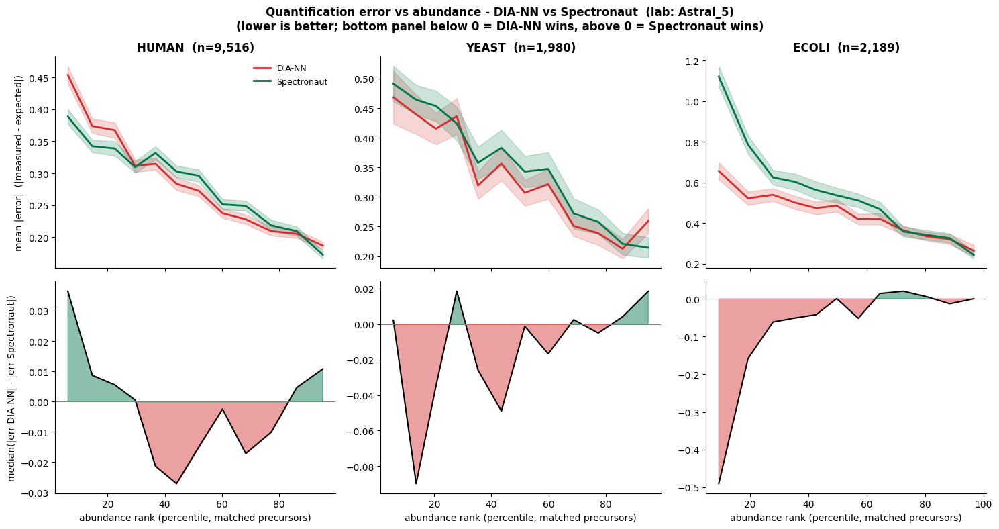

DIA-NN vs Spectronaut: 11,266 matched precursors
  HUMAN : DIA-NN more accurate in  55.9% of matched precursors | median |err|: DIA-NN=0.171  Spectronaut=0.196
  YEAST : DIA-NN more accurate in  54.4% of matched precursors | median |err|: DIA-NN=0.203  Spectronaut=0.226
  ECOLI : DIA-NN more accurate in  54.1% of matched precursors | median |err|: DIA-NN=0.335  Spectronaut=0.347


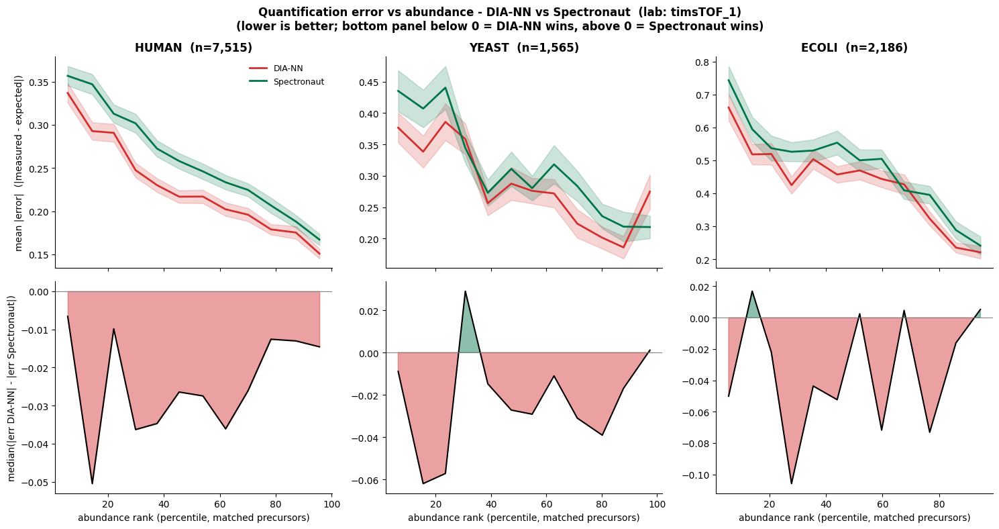

DIA-NN vs Spectronaut: 10,469 matched precursors
  HUMAN : DIA-NN more accurate in  56.8% of matched precursors | median |err|: DIA-NN=0.203  Spectronaut=0.246
  YEAST : DIA-NN more accurate in  55.0% of matched precursors | median |err|: DIA-NN=0.273  Spectronaut=0.306
  ECOLI : DIA-NN more accurate in  66.0% of matched precursors | median |err|: DIA-NN=0.381  Spectronaut=0.513


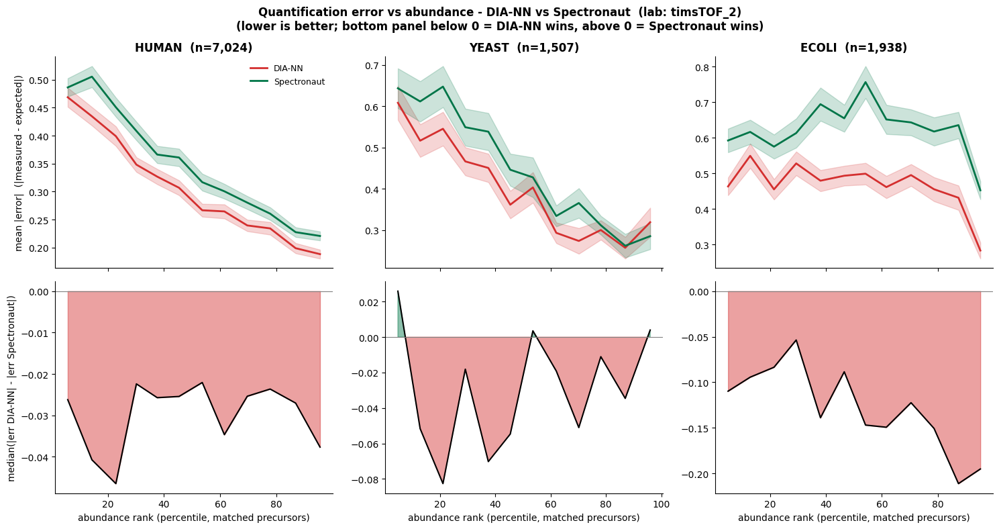

DIA-NN vs Spectronaut: 10,293 matched precursors
  HUMAN : DIA-NN more accurate in  59.7% of matched precursors | median |err|: DIA-NN=0.215  Spectronaut=0.275
  YEAST : DIA-NN more accurate in  60.2% of matched precursors | median |err|: DIA-NN=0.226  Spectronaut=0.295
  ECOLI : DIA-NN more accurate in  54.6% of matched precursors | median |err|: DIA-NN=0.392  Spectronaut=0.423


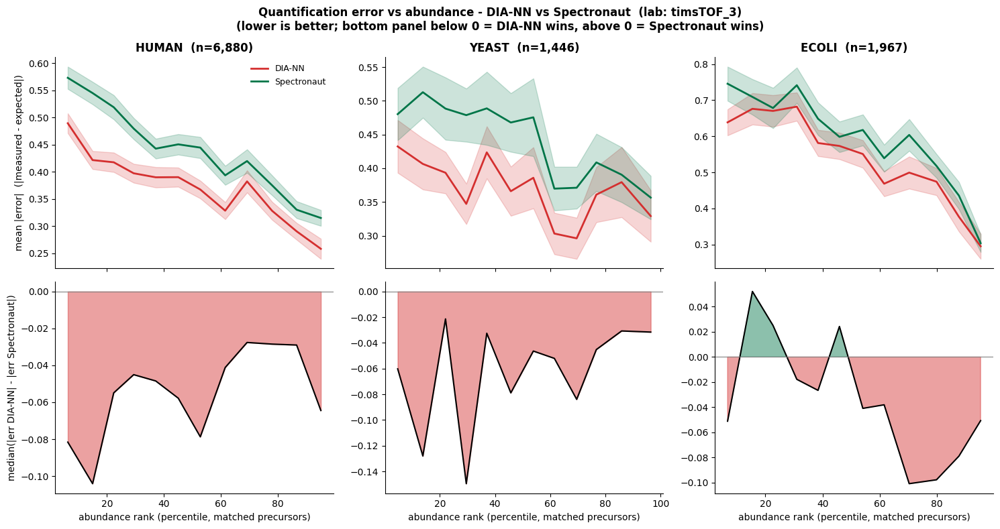

In [10]:
def tool_inter(name, source=inter):
    return source[source['search_engine'] == name]


for lab in available_labs:
    try:
        _ = compare_tools_error(
            inter_a        = tool_inter('DIA-NN'),
            inter_b        = tool_inter('Spectronaut'),
            name_a         = 'DIA-NN',
            name_b         = 'Spectronaut',
            species_colors = SPECIES_COLORS,
            lab            = lab,
            save_dir       = FIGURE_PATH,
            filename       = f'pairwise_error_DIANN_vs_Spectronaut_{lab}',
            show           = True,
        )
    except Exception:
        continue

## 5. MA-plots pooled per instrument type

The MA-plots in section 3 are computed one lab at a time. Here the labs of the same instrument
type are pooled into a single figure: one panel for all **Astral** labs and one for all
**timsTOF** labs, one subplot per tool.

Because abundances are only comparable within a single lab, the abundance rank is computed
**separately within each (lab, tool)** and only then are the points pooled and plotted together.
The representation is identical to section 3 (x = measured log2 FC, coloured by species,
expected per-species ratios as dotted vertical lines).


In [11]:
# ── Instrument groups & recommended tool set ──────────────────────────────────
# Astral and timsTOF labs are pooled separately. The recommended tool set is the
# same set of best settings used throughout and is shared by the pooled MA-plots
# (section 5) and the multi-tool dynamic-range plots (section 6).
instrument_groups = {
    'Astral':  [l for l in available_labs if l.startswith('Astral')],
    'timsTOF': [l for l in available_labs if l.startswith('timsTOF')],
}
recommended_tools = list(best_settings.keys())

for group_name, labs in instrument_groups.items():
    print(f'{group_name:8s} ({len(labs)} labs): {", ".join(labs)}')
print(f'\nRecommended tools: {", ".join(recommended_tools)}')

Astral   (6 labs): Astral_1, Astral_2, Astral_3, Astral_4, Astral_5, Astral_6
timsTOF  (3 labs): timsTOF_1, timsTOF_2, timsTOF_3

Recommended tools: AlphaDIA, MSAID, DIA-NN, FragPipe (DIA-NN quant), PEAKS, Spectronaut


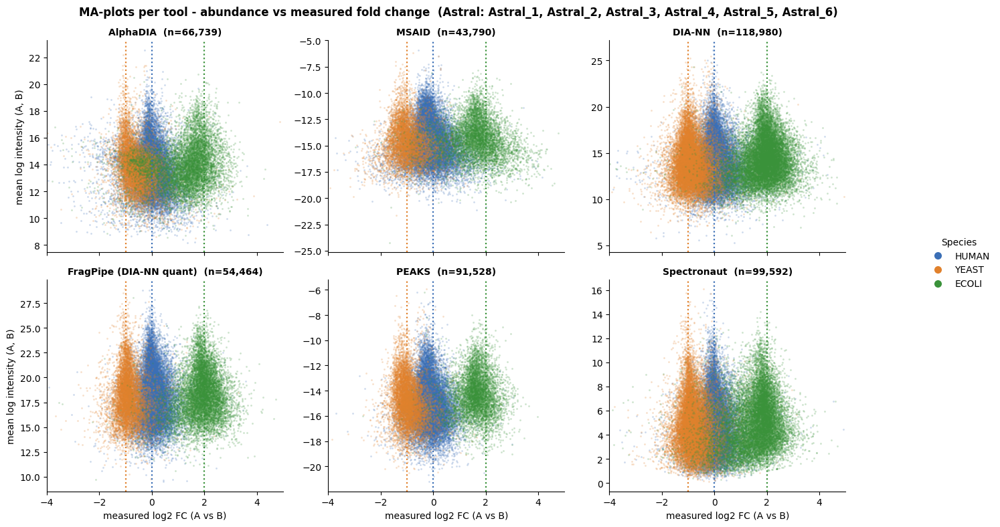

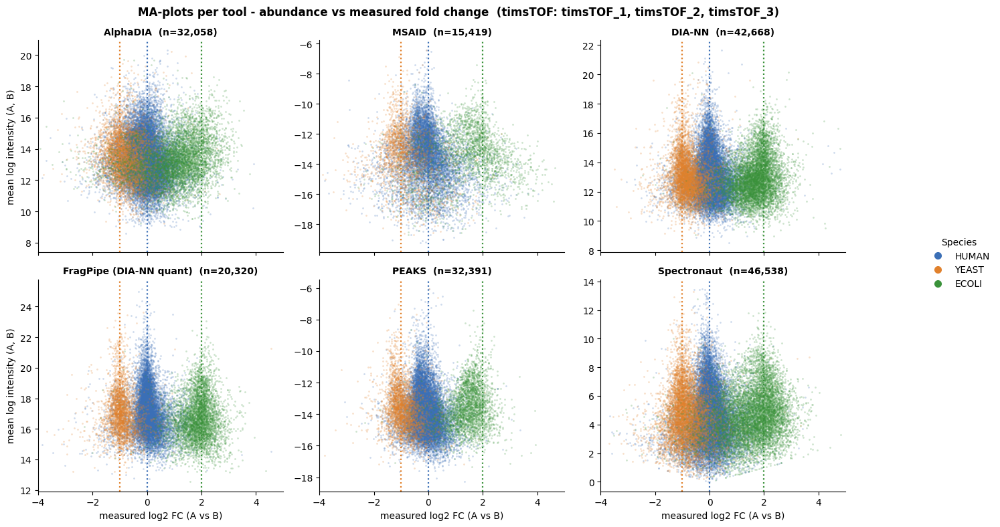

In [12]:
for group_name, labs in instrument_groups.items():
    plot_ma_multilab(
        intermediates  = inter,
        species_config = species_config,
        species_colors = SPECIES_COLORS,
        labs           = labs,
        tools          = recommended_tools,
        use_rank       = False,
        group_name     = group_name,
        save_dir       = FIGURE_PATH,
        filename       = f'MAplots_{group_name}',
        show           = True,
    )

## 6. Dynamic range across tools, pooled per instrument type

Generalises the pairwise error comparison (section 4) from two tools to the full recommended
tool set (`recommended_tools`, the same tools shown in the MA-plots).

For each lab the precursors are restricted to those quantified by **all** recommended tools
(stringent overlap), the abundance rank is computed within that lab, and only then are the
matched precursors pooled across the labs of an instrument group. Ranks, bins and errors are
therefore always calculated per lab; pooling only affects what is drawn.

Per species (one column each):
- **Top** — mean absolute error `|epsilon|` vs abundance rank, one line per tool with an SEM
  band. The lowest line is the most accurate tool at that abundance.
- **Bottom** — a thin band coloured by the tool with the lowest mean error in each abundance
  bin (the winning tool across the dynamic range).


Dynamic range (Astral): 23,264 precursors matched across all 6 tools, pooled over 6 lab(s)


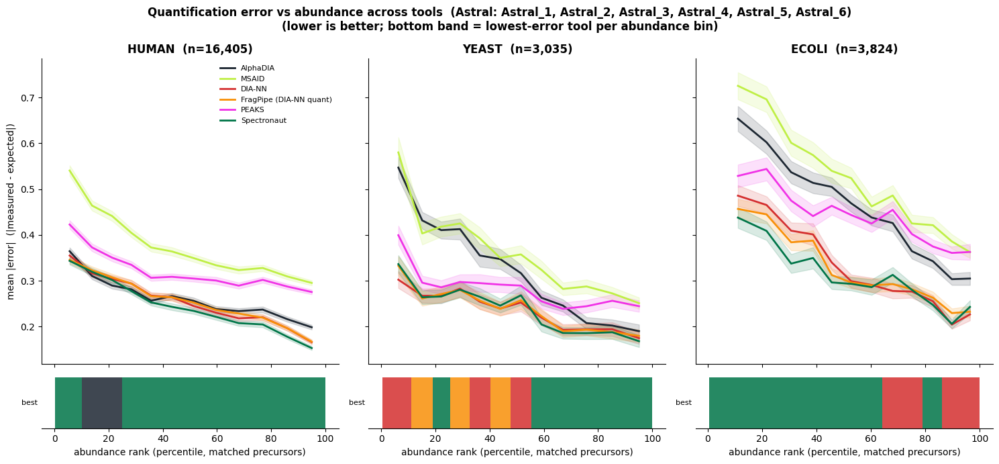

Dynamic range (timsTOF): 7,494 precursors matched across all 6 tools, pooled over 3 lab(s)


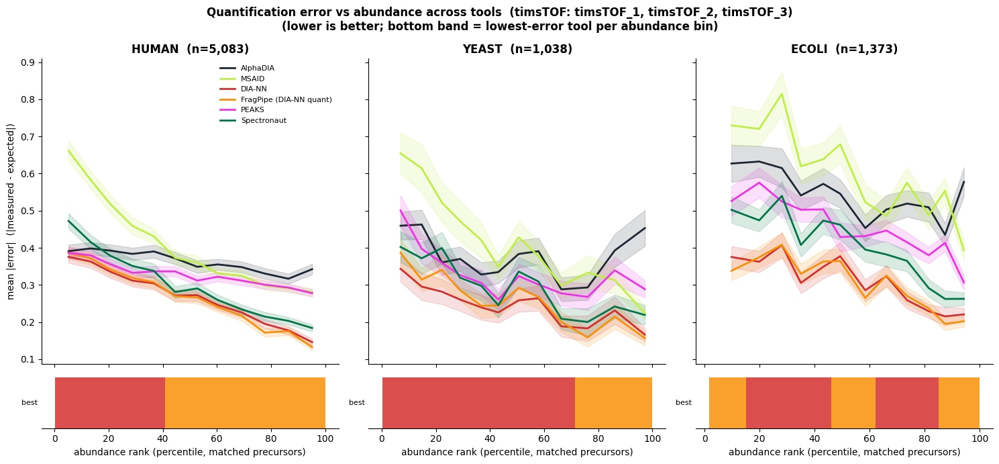

In [13]:
for group_name, labs in instrument_groups.items():
    _ = plot_dynamic_range_multi(
        intermediates  = inter,
        species_colors = SPECIES_COLORS,
        labs           = labs,
        tools          = recommended_tools,
        color_map      = SOFTWARE_COLORS,
        group_name     = group_name,
        save_dir       = FIGURE_PATH,
        filename       = f'dynamic_range_{group_name}',
        show           = True,
    )